# RD04 — Análise Exploratória (EDA) — DADOS MOCKADOS

> **Os dados deste notebook são mockados e não representam o comportamento dos passageiros.** O gerador ([`dados/mock/`](../mock/)) só devolve os padrões programados nele ([RD02](../../docs/dados/02-plano-preparacao.md)). Por isso esta EDA **valida o pipeline e as visualizações**, não as hipóteses do [RD01](../../docs/dados/01-plano-analise.md). Quando houver relatos reais, o mesmo notebook roda sobre eles (filtro `origem = 'real'`).

**De onde vêm os dados.** Só da camada **ouro** do pipeline (RD03), pela função `ler_ouro`. Nenhuma célula lê o banco do app, a bronze ou a prata.

**Como rodar do zero** (na raiz do repositório):

```bash
python manage.py loaddata linhas_dev
python manage.py gerar_mock --fim 2026-11-01   # 28 dias, ~25 mil relatos
python manage.py pipeline
uv run --group notebooks jupyter execute --inplace dados/notebooks/03-eda.ipynb
```

Os textos de interpretação se referem à execução registrada: 28 dias, de 05/10 a 01/11/2026, semente padrão do `config.yaml`. O CI roda o notebook sobre 7 dias de mock só para garantir que ele executa do zero sem erro; os números mudam, e as conclusões abaixo valem para a execução registrada.

| Seção | Issue |
| --- | --- |
| 1. Estrutural | #34 |
| 2. Distribucional | #35 |
| 3. Relacional (H1–H4) | #36 |
| 4. Outliers e anomalias | #37 |
| 5. Conclusão | #38 |

In [1]:
import os
import sys
from pathlib import Path

# Raiz do repositório: a pasta (atual ou acima) que tem o manage.py.
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "manage.py").exists()), None)
if RAIZ is None:
    raise RuntimeError("Rode o notebook de dentro do repositório (não achei o manage.py).")
sys.path[:0] = [str(RAIZ / "src"), str(RAIZ)]
os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings")
# O Jupyter roda num loop assíncrono; a doc do Django manda liberar o ORM assim em notebooks.
os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"

import django  # noqa: E402

django.setup()

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage  # noqa: E402
from scipy.stats import chi2_contingency, spearmanr  # noqa: E402

from dados.pipeline import banco  # noqa: E402
from dados.pipeline.esquemas import TABELAS_OURO  # noqa: E402

OURO = {tabela.nome: tabela for tabela in TABELAS_OURO}


def ler_ouro(nome):
    """Única porta de entrada dos dados: só lê tabelas da camada ouro (RD03).

    Os tipos anuláveis do pandas (Int64, Float64, boolean) viram tipos do NumPy,
    que o matplotlib e o SciPy entendem; valor ausente vira NaN.
    """
    df = banco.ler(OURO[nome])
    for coluna in df.columns:
        tipo = df[coluna].dtype
        if isinstance(tipo, pd.api.extensions.ExtensionDtype) and tipo.kind in "iuf":
            df[coluna] = df[coluna].astype(
                "float64" if df[coluna].isna().any() or tipo.kind == "f" else "int64"
            )
        elif isinstance(tipo, pd.BooleanDtype):
            df[coluna] = df[coluna].fillna(False).astype(bool)
    return df


por_hora = ler_ouro("relatos_por_hora")
taxas = ler_ouro("taxas_por_linha")
qualidade = ler_ouro("qualidade_diaria")

assert len(por_hora), "A ouro está vazia: rode gerar_mock e pipeline antes (ver a introdução)."

ORDEM_FAIXAS = ["madrugada", "inicio_manha", "pico_manha", "entre_picos", "pico_tarde", "noite"]
DIAS = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})


def cramer_v(tabela):
    """V de Cramér de uma tabela de contingência (linhas e colunas sem total zero)."""
    tabela = np.asarray(tabela, dtype=float)
    tabela = tabela[tabela.sum(axis=1) > 0][:, tabela.sum(axis=0) > 0]
    chi2 = chi2_contingency(tabela, correction=False)[0]
    n = tabela.sum()
    return float(np.sqrt(chi2 / (n * (min(tabela.shape) - 1))))


def wilson(sucessos, total, z=1.96):
    """Intervalo de confiança de Wilson (95%) para uma proporção."""
    p = sucessos / total
    centro = (p + z**2 / (2 * total)) / (1 + z**2 / total)
    margem = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / (1 + z**2 / total)
    return centro - margem, centro + margem


periodo = f"{por_hora['data'].min()} a {por_hora['data'].max()}"
print(f"Período: {periodo} · origens: {sorted(por_hora['origem'].unique())}")
print(
    {
        nome: len(df)
        for nome, df in [
            ("relatos_por_hora", por_hora),
            ("taxas_por_linha", taxas),
            ("qualidade_diaria", qualidade),
        ]
    }
)

Período: 2026-10-05 a 2026-11-01 · origens: ['mock']
{'relatos_por_hora': 5130, 'taxas_por_linha': 30, 'qualidade_diaria': 28}


## 1. Análise estrutural

Tipos, domínios, granularidade, chaves, contagens entre camadas e nulos.

**Granularidade.** A ouro já vem agregada (ADR 0026):
- `relatos_por_hora` tem uma linha por **dia × hora × linha × sentido × origem**;
- `taxas_por_linha` tem uma por **linha × faixa horária × origem**;
- `qualidade_diaria` tem uma por **dia × origem**.

O grão de um relato por linha, sentido e instante existe só na prata, onde o teste de unicidade de `qualidade.py` o confere a cada execução. Aqui conferimos as chaves da ouro.

In [2]:
resumo = []
for nome, df in [
    ("relatos_por_hora", por_hora),
    ("taxas_por_linha", taxas),
    ("qualidade_diaria", qualidade),
]:
    tabela = OURO[nome]
    duplicadas = int(df.duplicated(list(tabela.chave)).sum())
    resumo.append(
        {
            "tabela": f"ouro.{nome}",
            "linhas": len(df),
            "colunas": df.shape[1],
            "chave": " × ".join(tabela.chave),
            "chaves repetidas": duplicadas,
            "células nulas": int(df.isna().sum().sum()),
        }
    )
pd.DataFrame(resumo)

,tabela,linhas,colunas,chave,chaves repetidas,células nulas
0,ouro.relatos_por_hora,5130,32,data × hora × linha_codigo × sentido × origem,0,0
1,ouro.taxas_por_linha,30,18,linha_codigo × faixa_horaria × origem,0,0
2,ouro.qualidade_diaria,28,13,data × origem,0,0


**Interpretação.** As três tabelas têm chave única (zero repetições) e nenhuma célula nula. Na `relatos_por_hora`, isso inclui a temperatura: o mock cobre todas as horas. A ouro guarda contagens, nunca valores individuais. Por isso uma "categoria ausente" aparece como contagem `n_..._nao_informado` (ver Nulos abaixo), e não como `NULL`.

In [3]:
dominios = {
    "faixa_horaria": sorted(por_hora["faixa_horaria"].unique()),
    "modal": sorted(por_hora["modal"].unique()),
    "sentido": sorted(por_hora["sentido"].unique()),
    "hora (mín–máx)": [int(por_hora["hora"].min()), int(por_hora["hora"].max())],
    "operadora": sorted(por_hora["operadora"].unique()),
    "temperatura_fonte": sorted(por_hora["temperatura_fonte"].unique()),
}
for chave, valores in dominios.items():
    print(f"{chave}: {valores}")

soma_dimensoes = {
    "lotação": por_hora[["n_vazio", "n_moderado", "n_lotado"]].sum(axis=1),
    "ar": por_hora[
        ["n_ar_funcionando", "n_ar_nao_funcionando", "n_sem_ar", "n_ar_nao_informado"]
    ].sum(axis=1),
    "conforto": por_hora[["n_frio", "n_agradavel", "n_quente", "n_conforto_nao_informado"]].sum(
        axis=1
    ),
    "vaga PCD": por_hora[["n_vaga_disponivel", "n_vaga_ocupada", "n_vaga_nao_informada"]].sum(
        axis=1
    ),
}
for dimensao, soma in soma_dimensoes.items():
    print(
        f"Categorias de {dimensao} "
        f"somam n_relatos em todas as células: {(soma == por_hora['n_relatos']).all()}"
    )

faixa_horaria: ['entre_picos', 'inicio_manha', 'madrugada', 'noite', 'pico_manha', 'pico_tarde']
modal: ['brt', 'metro', 'onibus']
sentido: ['ida', 'volta']
hora (mín–máx): [0, 23]
operadora: ['CBTU', 'nao_informada']
temperatura_fonte: ['mock']
Categorias de lotação somam n_relatos em todas as células: True
Categorias de ar somam n_relatos em todas as células: True
Categorias de conforto somam n_relatos em todas as células: True
Categorias de vaga PCD somam n_relatos em todas as células: True


**Interpretação.** Todos os domínios estão dentro do esperado:
- 6 faixas horárias, 3 modais, 2 sentidos e horas de 0 a 23 no fuso de Recife;
- em toda célula, a soma das categorias de cada dimensão bate com `n_relatos`, então nenhum relato fica sem categoria.

Já aparece uma limitação da fonte de linhas: só o metrô (CBTU) tem operadora. As linhas de ônibus e BRT da fixture de desenvolvimento vêm sem ela (`nao_informada`). Isso afeta a H2 (seção 3).

In [4]:
q = qualidade.sum(numeric_only=True)
contagens = pd.Series(
    {
        "relatos no total (qualidade_diaria)": int(q["n_relatos_total"]),
        "removidos pela moderação": int(q["n_removidos"]),
        "substituídos (RN05)": int(q["n_substituidos"]),
        "fora do domínio (RN01)": int(q["n_fora_do_dominio"]),
        "válidos (qualidade_diaria)": int(q["n_validos"]),
        "válidos (soma de relatos_por_hora)": int(por_hora["n_relatos"].sum()),
        "válidos (soma de taxas_por_linha)": int(taxas["n_relatos"].sum()),
    }
)
fora = q["n_removidos"] + q["n_substituidos"] + q["n_fora_do_dominio"]
print(
    f"total − fora da análise = {int(q['n_relatos_total'] - fora)} "
    f"(removidos e substituídos podem se sobrepor)"
)
contagens.to_frame("relatos")

total − fora da análise = 23695 (removidos e substituídos podem se sobrepor)


,relatos
relatos no total (qualidade_diaria),25511
removidos pela moderação,660
substituídos (RN05),1156
fora do domínio (RN01),0
válidos (qualidade_diaria),23696
válidos (soma de relatos_por_hora),23696
válidos (soma de taxas_por_linha),23696


**Interpretação.** Nada some entre as camadas. Os 23.696 relatos válidos são o mesmo número na `qualidade_diaria`, na soma de `relatos_por_hora` e na soma de `taxas_por_linha`.

Dos 25.511 relatos gerados, 7% ficam fora da análise:
- 1.156 substituídos pelo próprio autor (RN05);
- 660 removidos pela moderação (RF07).

Nenhum relato está fora do domínio da RN01, o que era esperado: o banco do app já recusa esses valores. A diferença de 1 entre "total − fora" (23.695) e os válidos (23.696) não é perda. É o efeito de somar categorias que se sobrepõem: um relato pode ter sido substituído e também removido. Por isso a regra de contagem do pipeline usa a marcação de cada relato, não essa subtração.

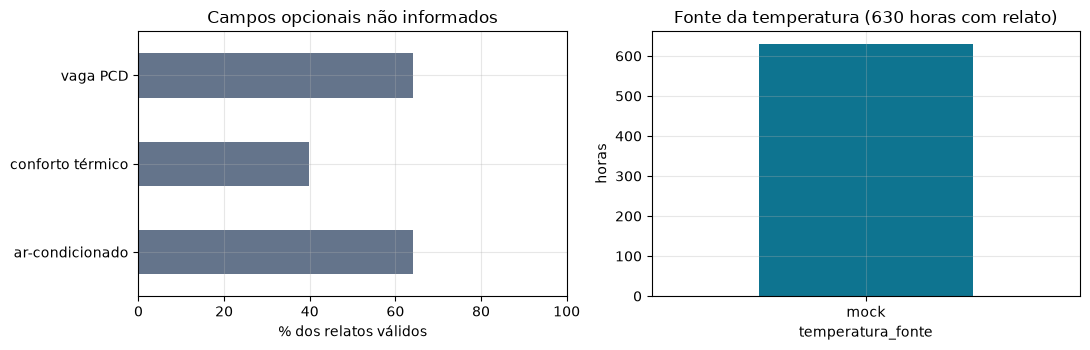

,nao_informado,total,% não informado
ar-condicionado,15200,23696,64.1
conforto térmico,9452,23696,39.9
vaga PCD,15201,23696,64.2


In [5]:
informado = pd.DataFrame(
    {
        "ar-condicionado": [por_hora["n_ar_nao_informado"].sum(), por_hora["n_relatos"].sum()],
        "conforto térmico": [
            por_hora["n_conforto_nao_informado"].sum(),
            por_hora["n_relatos"].sum(),
        ],
        "vaga PCD": [por_hora["n_vaga_nao_informada"].sum(), por_hora["n_relatos"].sum()],
    },
    index=["nao_informado", "total"],
).T
informado["% não informado"] = 100 * informado["nao_informado"] / informado["total"]

horas_temp = len(por_hora.drop_duplicates(["data", "hora"]))
temp = por_hora.drop_duplicates(["data", "hora"])["temperatura_fonte"].value_counts()

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6))
informado["% não informado"].plot.barh(ax=eixos[0], color="#64748b")
eixos[0].set_xlabel("% dos relatos válidos")
eixos[0].set_title("Campos opcionais não informados")
eixos[0].set_xlim(0, 100)
temp.plot.bar(ax=eixos[1], color="#0e7490")
eixos[1].set_title(f"Fonte da temperatura ({horas_temp} horas com relato)")
eixos[1].set_ylabel("horas")
eixos[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
informado.round(1)

**Interpretação.** Os campos opcionais têm muita falta:
- 64% dos relatos não informam o ar-condicionado;
- 64% não informam a vaga PCD;
- 40% não informam o conforto térmico.

Pelo RD02, essa falta é **MNAR**: quem relata o ar tende a fazê-lo quando ele está quebrado. A decisão L6 se confirma: não imputar e tratar `nao_informado` como categoria. Imputar com a moda transformaria 64% dos relatos em "sem ar" e apagaria o viés que a H2 precisa declarar.

A temperatura vem toda do mock (`fonte = mock`), sem lacunas nem interpolação. Isso muda quando a série do INMET entrar (#26): aí a regra L11 (interpolar só até 2 h) passa a ter efeito e precisa ser conferida de novo.

## 2. Análise distribucional

Distribuição de cada dimensão e volume de relatos por linha, faixa horária e dia da semana.

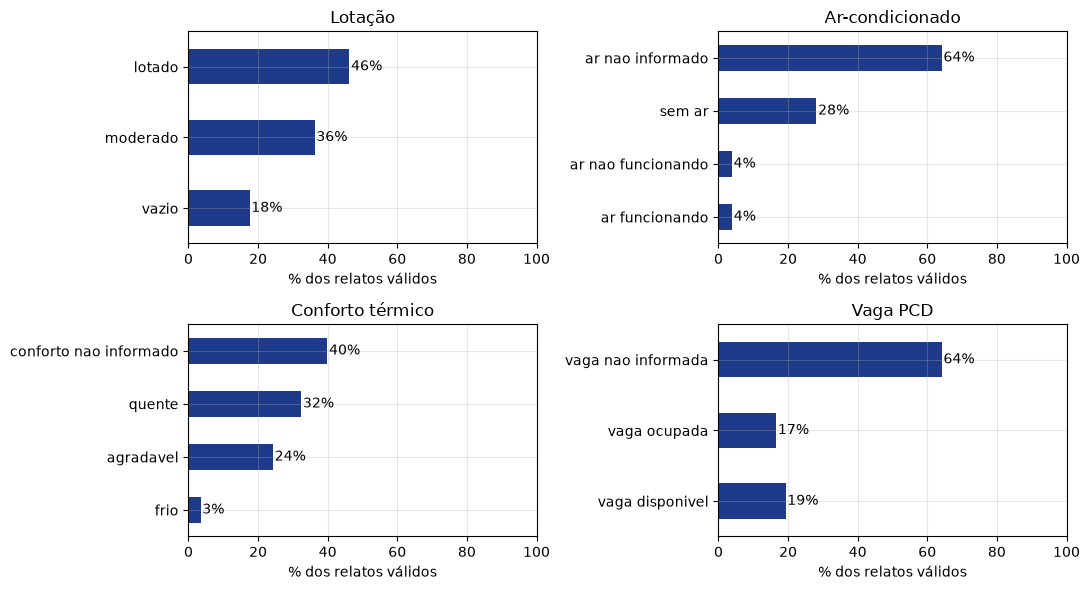

In [6]:
distribuicoes = {
    "Lotação": por_hora[["n_vazio", "n_moderado", "n_lotado"]].sum(),
    "Ar-condicionado": por_hora[
        ["n_ar_funcionando", "n_ar_nao_funcionando", "n_sem_ar", "n_ar_nao_informado"]
    ].sum(),
    "Conforto térmico": por_hora[
        ["n_frio", "n_agradavel", "n_quente", "n_conforto_nao_informado"]
    ].sum(),
    "Vaga PCD": por_hora[["n_vaga_disponivel", "n_vaga_ocupada", "n_vaga_nao_informada"]].sum(),
}
fig, eixos = plt.subplots(2, 2, figsize=(11, 6))
for eixo, (titulo, serie) in zip(eixos.flat, distribuicoes.items(), strict=True):
    pct = 100 * serie / serie.sum()
    pct.index = [i.removeprefix("n_").replace("_", " ") for i in pct.index]
    pct.plot.barh(ax=eixo, color="#1e3a8a")
    eixo.set_title(titulo)
    eixo.set_xlabel("% dos relatos válidos")
    for i, valor in enumerate(pct):
        eixo.text(valor + 0.5, i, f"{valor:.0f}%", va="center")
    eixo.set_xlim(0, 100)
plt.tight_layout()
plt.show()

**Interpretação.**
- **Lotação:** "lotado" é o valor mais comum (46%, contra 36% de moderado e 18% de vazio). É coerente com o volume concentrado nos picos (próximo gráfico), quando o gerador sorteia mais "lotado".
- **Ar-condicionado:** "sem ar" é o valor informado mais comum (28%), o que reflete os 84% da frota sem climatização. Entre os veículos climatizados, "não funcionando" (3,8%) aparece tanto quanto "funcionando" (3,9%), embora o mock use 25% de falha média. É o viés MNAR em ação: quem tem o ar quebrado informa mais.
- **Conforto térmico:** "quente" é o valor informado mais comum (32%), como esperado no Recife e programado na H3.
- **Vaga PCD:** junto com o ar, é a dimensão menos informada (64% não informam). Entre quem informa, "disponível" (19%) e "ocupada" (17%) ficam próximas.

Para o painel, toda taxa sobre um campo opcional precisa mostrar o denominador (quantos informaram), como já faz a `taxas_por_linha`.

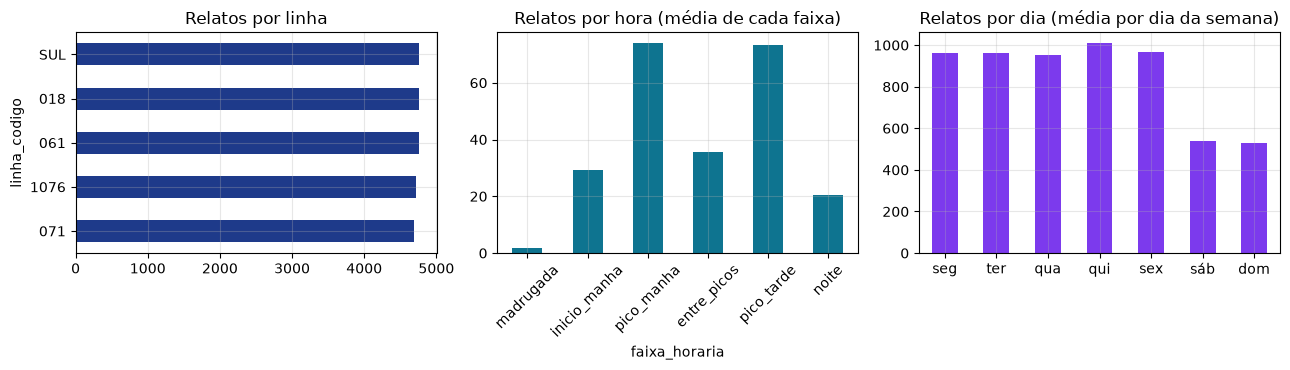

Por linha: {'071': 4695, '1076': 4716, '061': 4756, '018': 4764, 'SUL': 4765}
Média por hora em cada faixa: {'madrugada': 1.8, 'inicio_manha': 29.2, 'pico_manha': 74.1, 'entre_picos': 35.5, 'pico_tarde': 73.3, 'noite': 20.5}
Média por dia da semana: {'seg': 962.0, 'ter': 961.0, 'qua': 951.0, 'qui': 1011.0, 'sex': 969.0, 'sáb': 537.0, 'dom': 532.0}


In [7]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8))
por_linha = por_hora.groupby("linha_codigo")["n_relatos"].sum().sort_values()
por_linha.plot.barh(ax=eixos[0], color="#1e3a8a")
eixos[0].set_title("Relatos por linha")

dias_por_faixa = por_hora.drop_duplicates(["data", "hora"]).groupby("faixa_horaria").size()
horas_na_faixa = {
    "madrugada": 5,
    "inicio_manha": 1,
    "pico_manha": 3,
    "entre_picos": 8,
    "pico_tarde": 3,
    "noite": 4,
}
por_faixa = por_hora.groupby("faixa_horaria")["n_relatos"].sum().reindex(ORDEM_FAIXAS)
media_hora = (
    por_faixa / pd.Series(horas_na_faixa).reindex(ORDEM_FAIXAS) / por_hora["data"].nunique()
)
media_hora.plot.bar(ax=eixos[1], color="#0e7490")
eixos[1].set_title("Relatos por hora (média de cada faixa)")
eixos[1].tick_params(axis="x", rotation=45)

dias_distintos = por_hora.drop_duplicates("data").groupby("dia_semana").size()
por_dia = por_hora.groupby("dia_semana")["n_relatos"].sum() / dias_distintos
por_dia.index = [DIAS[i] for i in por_dia.index]
por_dia.plot.bar(ax=eixos[2], color="#7c3aed")
eixos[2].set_title("Relatos por dia (média por dia da semana)")
eixos[2].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
print("Por linha:", por_linha.to_dict())
print("Média por hora em cada faixa:", media_hora.round(1).to_dict())
print("Média por dia da semana:", por_dia.round(0).to_dict())

**Interpretação.**
- **Por linha:** o volume é praticamente igual entre as 5 linhas (cerca de 4.700 relatos cada). Isso é do mock, que usa o mesmo volume de pico para todas; com dados reais, linhas mais usadas terão muito mais relatos. O painel precisa então de taxas, não de contagens, para comparar linhas.
- **Por faixa:** os picos da manhã e da tarde têm cerca de 74 relatos por hora, contra 36 entre picos e menos de 2 na madrugada. A madrugada quase não tem dado, e qualquer taxa nela é instável.
- **Por dia da semana:** sábado e domingo têm cerca de 55% do volume dos dias úteis (o fator de fim de semana do `config.yaml`).

## 3. Análise relacional

Uma medida de associação e ao menos um gráfico para cada hipótese do RD01:
- **V de Cramér** entre categóricas: 0 é nenhuma associação, 1 é associação total. Como referência, 0,1 é fraca, 0,3 moderada e 0,5 forte.
- **Spearman** com a temperatura.
- **Agrupamento hierárquico** das linhas pelo perfil de lotação ao longo do dia.

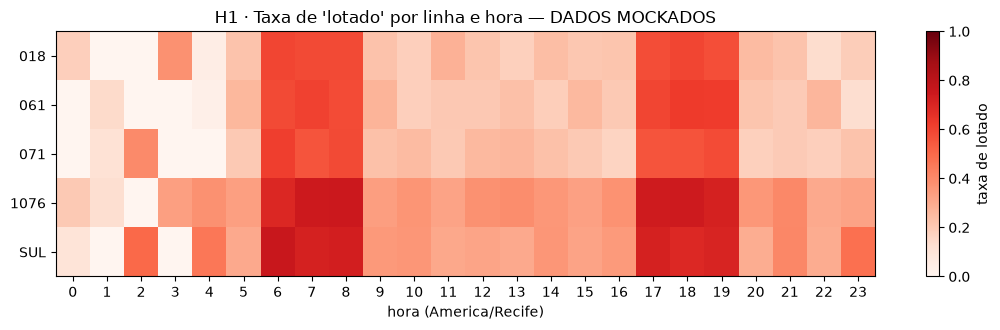

V de Cramér lotação × faixa horária: 0.30
V de Cramér lotação × passa por terminal: 0.16
Taxa de lotado no pico, por passagem em terminal: {False: 0.588, True: 0.724}
Taxa de lotado por faixa: {'madrugada': 0.149, 'inicio_manha': 0.264, 'pico_manha': 0.644, 'entre_picos': 0.27, 'pico_tarde': 0.641, 'noite': 0.263}


In [8]:
lotado_hora = por_hora.groupby(["linha_codigo", "hora"])[["n_lotado", "n_relatos"]].sum()
mapa = (
    (lotado_hora["n_lotado"] / lotado_hora["n_relatos"]).unstack("hora").reindex(columns=range(24))
)
fig, eixo = plt.subplots(figsize=(11, 3.4))
imagem = eixo.imshow(mapa, aspect="auto", cmap="Reds", vmin=0, vmax=1)
eixo.set_yticks(range(len(mapa)), mapa.index)
eixo.set_xticks(range(24), range(24))
eixo.set_xlabel("hora (America/Recife)")
eixo.set_title("H1 · Taxa de 'lotado' por linha e hora — DADOS MOCKADOS")
eixo.grid(False)
fig.colorbar(imagem, ax=eixo, label="taxa de lotado")
plt.tight_layout()
plt.show()

lot_faixa = (
    por_hora.groupby("faixa_horaria")[["n_vazio", "n_moderado", "n_lotado"]]
    .sum()
    .reindex(ORDEM_FAIXAS)
)
lot_terminal = por_hora.groupby("passa_por_terminal")[["n_vazio", "n_moderado", "n_lotado"]].sum()
pico = por_hora["faixa_horaria"].isin(["pico_manha", "pico_tarde"])
taxa_pico = por_hora[pico].groupby("passa_por_terminal")[["n_lotado", "n_relatos"]].sum()
print(f"V de Cramér lotação × faixa horária: {cramer_v(lot_faixa):.2f}")
print(f"V de Cramér lotação × passa por terminal: {cramer_v(lot_terminal):.2f}")
print(
    "Taxa de lotado no pico, por passagem em terminal:",
    (taxa_pico["n_lotado"] / taxa_pico["n_relatos"]).round(3).to_dict(),
)
print(
    "Taxa de lotado por faixa:", (lot_faixa["n_lotado"] / lot_faixa.sum(axis=1)).round(3).to_dict()
)

**Interpretação (H1: lotação nos picos, nas linhas que chegam aos TIs).** O mapa de calor mostra duas faixas vermelhas, 6–8h e 17–19h, em todas as linhas.
- A taxa de "lotado" vai de 15% na madrugada e 27% entre picos para cerca de 64% nos picos.
- A associação lotação × faixa horária é **moderada (V = 0,30)**.
- O efeito dos terminais também aparece: no pico, linhas cujo sentido passa por um Terminal Integrado têm 72% de "lotado", contra 59% das demais. Essa associação é **fraca (V = 0,16)**, porque o efeito só vale num dos sentidos.

**No mock, a H1 aparece como foi programada.** O mapa linha × hora é a visualização certa para a página "Lotação" do painel e segue para o dashboard.

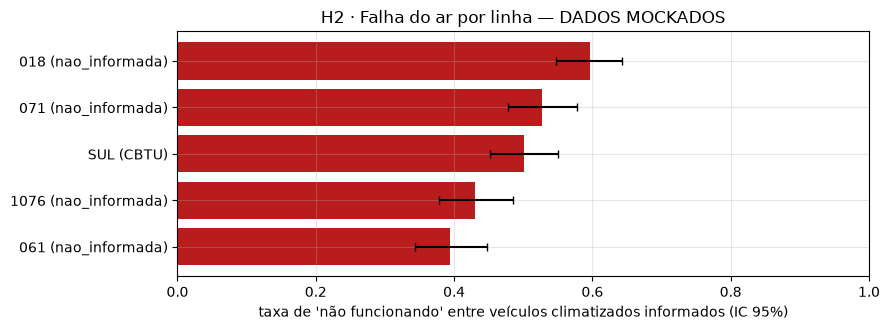

V de Cramér ar (funcionando × não) × linha: 0.14


,,informado,taxa,ic_baixo,ic_alto
linha_codigo,operadora,,,,
061,nao_informada,337,0.395,0.344,0.448
1076,nao_informada,323,0.430,0.377,0.485
SUL,CBTU,387,0.501,0.452,0.551
071,nao_informada,381,0.528,0.477,0.577
018,nao_informada,404,0.597,0.548,0.643


In [9]:
ar = por_hora.groupby(["linha_codigo", "operadora"])[
    ["n_ar_nao_funcionando", "n_ar_funcionando"]
].sum()
ar["informado"] = ar.sum(axis=1)
ar = ar[ar["informado"] >= 30].copy()
ar["taxa"] = ar["n_ar_nao_funcionando"] / ar["informado"]
ar["ic_baixo"], ar["ic_alto"] = wilson(ar["n_ar_nao_funcionando"], ar["informado"])
ar = ar.sort_values("taxa")
fig, eixo = plt.subplots(figsize=(9, 3.4))
rotulos = [f"{linha} ({operadora})" for linha, operadora in ar.index]
eixo.barh(rotulos, ar["taxa"], color="#b91c1c")
eixo.errorbar(
    ar["taxa"],
    rotulos,
    xerr=[ar["taxa"] - ar["ic_baixo"], ar["ic_alto"] - ar["taxa"]],
    fmt="none",
    color="black",
    capsize=3,
)
eixo.set_xlim(0, 1)
eixo.set_xlabel("taxa de 'não funcionando' entre veículos climatizados informados (IC 95%)")
eixo.set_title("H2 · Falha do ar por linha — DADOS MOCKADOS")
plt.tight_layout()
plt.show()
v_ar_linha = cramer_v(ar[["n_ar_nao_funcionando", "n_ar_funcionando"]])
print(f"V de Cramér ar (funcionando × não) × linha: {v_ar_linha:.2f}")
ar[["informado", "taxa", "ic_baixo", "ic_alto"]].round(3)

**Interpretação (H2: a falha do ar varia entre linhas e operadoras).**
- **Entre linhas:** a taxa de "não funcionando" vai de 40% (061) a 60% (018), e os intervalos de confiança de 95% das pontas não se sobrepõem. A associação ar × linha é **fraca (V = 0,14)**, mas existe.
- **Viés MNAR:** as taxas observadas estão todas bem acima dos 25% de falha usados pelo gerador. A **taxa observada não é a taxa real de falha**, e o painel precisa dizer isso.
- **Entre operadoras:** não dá para testar. Só o metrô tem operadora na fixture. Fica pendente da importação do GTFS real (#25).

**Decisão para o painel:** ranking por linha, com intervalo de confiança e mínimo de 30 relatos informados por linha para entrar no ranking.

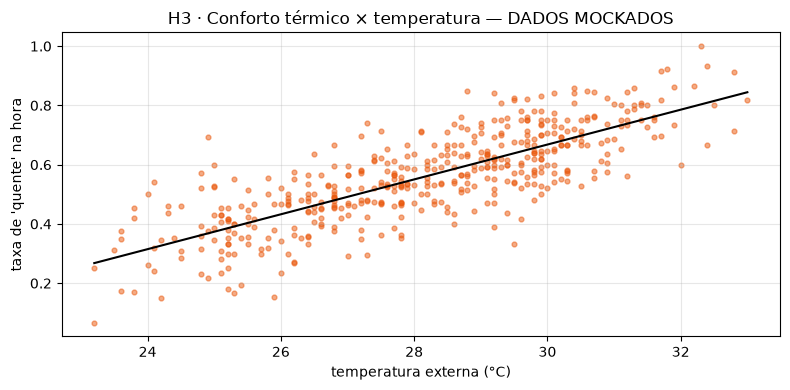

Horas com ao menos 10 relatos de conforto: 462
Spearman temperatura × taxa de quente: rho = 0.79 (p = 6.5e-101); inclinação = 0.059 por °C


In [10]:
por_instante = por_hora.groupby(["data", "hora"]).agg(
    n_quente=("n_quente", "sum"),
    n_frio=("n_frio", "sum"),
    n_agradavel=("n_agradavel", "sum"),
    temperatura_c=("temperatura_c", "first"),
)
por_instante["informado"] = por_instante[["n_quente", "n_frio", "n_agradavel"]].sum(axis=1)
por_instante = por_instante[
    (por_instante["informado"] >= 10) & por_instante["temperatura_c"].notna()
]
por_instante["taxa_quente"] = por_instante["n_quente"] / por_instante["informado"]
rho, p_valor = spearmanr(por_instante["temperatura_c"], por_instante["taxa_quente"])

fig, eixo = plt.subplots(figsize=(8, 4))
eixo.scatter(
    por_instante["temperatura_c"], por_instante["taxa_quente"], s=12, alpha=0.5, color="#ea580c"
)
coef = np.polyfit(por_instante["temperatura_c"], por_instante["taxa_quente"], 1)
x = np.linspace(por_instante["temperatura_c"].min(), por_instante["temperatura_c"].max(), 50)
eixo.plot(x, np.polyval(coef, x), color="black")
eixo.set_xlabel("temperatura externa (°C)")
eixo.set_ylabel("taxa de 'quente' na hora")
eixo.set_title("H3 · Conforto térmico × temperatura — DADOS MOCKADOS")
plt.tight_layout()
plt.show()
print(f"Horas com ao menos 10 relatos de conforto: {len(por_instante)}")
print(
    f"Spearman temperatura × taxa de quente: rho = {rho:.2f} (p = {p_valor:.1e})"
    f"; inclinação = {coef[0]:.3f} por °C"
)

**Interpretação (H3: "quente" cresce com a temperatura, mais forte sem ar).** Cada ponto é uma hora com ao menos 10 relatos de conforto (462 horas). A correlação é **forte (Spearman ρ = 0,79)**: cada grau a mais soma cerca de 6 pontos percentuais à taxa de "quente".

**A segunda metade da H3 não pode ser testada com a ouro atual.** A `relatos_por_hora` conta o conforto e o ar separadamente (contagens marginais), sem o cruzamento conforto × ar. Não dá para separar "com ar" de "sem ar". Isso volta para o RD03 (ver Conclusão).

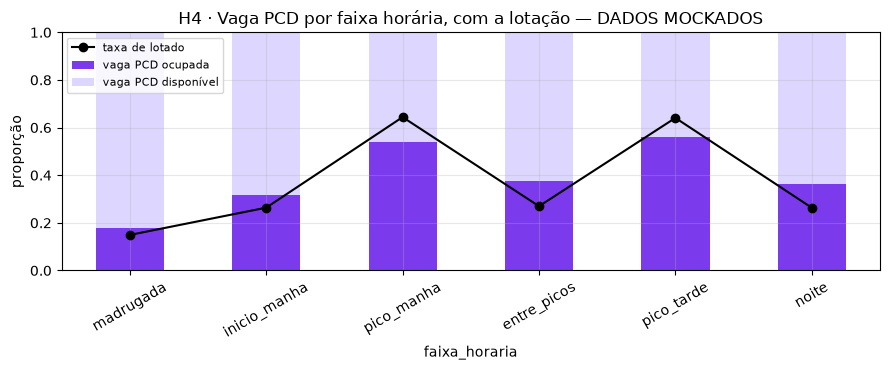

V de Cramér vaga PCD × faixa horária: 0.19
Spearman, por célula (dia × hora × linha × sentido, ≥ 3 vagas informadas, n = 1228): taxa de lotado × taxa de vaga ocupada: rho = 0.39 (p = 1.4e-46)


In [11]:
vaga = (
    por_hora.groupby("faixa_horaria")[["n_vaga_disponivel", "n_vaga_ocupada"]]
    .sum()
    .reindex(ORDEM_FAIXAS)
)
pct_vaga = vaga.div(vaga.sum(axis=1), axis=0)
lot = por_hora.groupby("faixa_horaria")[["n_lotado", "n_relatos"]].sum().reindex(ORDEM_FAIXAS)

fig, eixo = plt.subplots(figsize=(9, 3.8))
pct_vaga["n_vaga_ocupada"].plot.bar(ax=eixo, color="#7c3aed", label="vaga PCD ocupada")
pct_vaga["n_vaga_disponivel"].plot.bar(
    ax=eixo, bottom=pct_vaga["n_vaga_ocupada"], color="#ddd6fe", label="vaga PCD disponível"
)
eixo.plot(
    range(len(lot)), lot["n_lotado"] / lot["n_relatos"], "o-", color="black", label="taxa de lotado"
)
eixo.set_ylim(0, 1)
eixo.set_ylabel("proporção")
eixo.tick_params(axis="x", rotation=30)
eixo.set_title("H4 · Vaga PCD por faixa horária, com a lotação — DADOS MOCKADOS")
eixo.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

celulas = por_hora[(por_hora["n_vaga_disponivel"] + por_hora["n_vaga_ocupada"]) >= 3].copy()
celulas["taxa_ocupada"] = celulas["n_vaga_ocupada"] / (
    celulas["n_vaga_disponivel"] + celulas["n_vaga_ocupada"]
)
celulas["taxa_lotado"] = celulas["n_lotado"] / celulas["n_relatos"]
rho_vaga, p_vaga = spearmanr(celulas["taxa_lotado"], celulas["taxa_ocupada"])
print(f"V de Cramér vaga PCD × faixa horária: {cramer_v(vaga):.2f}")
print(
    f"Spearman, por célula (dia × hora × linha × sentido, ≥ 3 vagas informadas, n = {len(celulas)})"
    f": taxa de lotado × taxa de vaga ocupada: rho = {rho_vaga:.2f} (p = {p_vaga:.1e})"
)

**Interpretação (H4: a vaga PCD ocupada acompanha a lotação).** Por faixa horária, a proporção de vaga ocupada sobe e desce junto com a taxa de "lotado": vai de 18% na madrugada a 54–56% nos picos. A associação vaga × faixa é **fraca (V = 0,19)**.

Comparando células (dia × hora × linha × sentido, com ao menos 3 vagas informadas), a taxa de vaga ocupada cresce com a taxa de lotado (**Spearman ρ = 0,39**, moderada).

Como na H3, essa é uma **medida indireta**: a ouro não cruza vaga × lotação no nível do relato. Por isso o V de Cramér entre `vaga_pcd` e `lotacao` previsto no RD01 não pode ser calculado. Volta para o RD03.

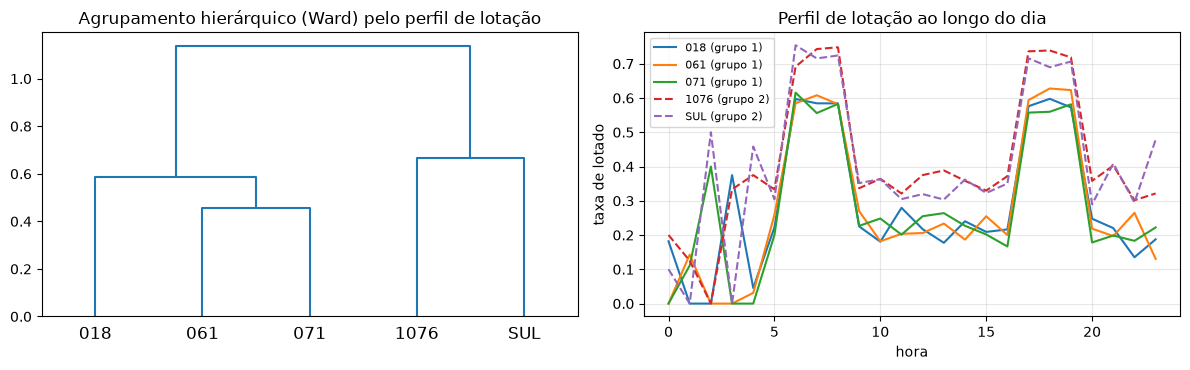

Grupos: {'018': 1, '061': 1, '071': 1, '1076': 2, 'SUL': 2}


In [12]:
perfil = (
    (lotado_hora["n_lotado"] / lotado_hora["n_relatos"])
    .unstack("hora")
    .reindex(columns=range(24))
    .fillna(0)
)
ligacoes = linkage(perfil.to_numpy(), method="ward")
grupos = fcluster(ligacoes, t=2, criterion="maxclust")
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8))
dendrogram(ligacoes, labels=perfil.index.tolist(), ax=eixos[0], color_threshold=0)
eixos[0].set_title("Agrupamento hierárquico (Ward) pelo perfil de lotação")
eixos[0].grid(False)
for codigo, grupo in zip(perfil.index, grupos, strict=True):
    eixos[1].plot(
        perfil.columns,
        perfil.loc[codigo],
        label=f"{codigo} (grupo {grupo})",
        linestyle="-" if grupo == 1 else "--",
    )
eixos[1].set_xlabel("hora")
eixos[1].set_ylabel("taxa de lotado")
eixos[1].set_title("Perfil de lotação ao longo do dia")
eixos[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Grupos:", dict(zip(perfil.index, grupos.tolist(), strict=True)))

**Interpretação.** O agrupamento hierárquico (método de Ward, 2 grupos) separa as linhas pelo perfil de lotação ao longo do dia:
- **SUL e 1076:** as duas que passam por Terminal Integrado (TI Joana Bezerra e TI Pelópidas), com picos mais altos (cerca de 70–74% de lotado às 7h e às 18h);
- **018, 061 e 071:** as demais (56–63% nas mesmas horas).

O resultado bate com a H1. Com só 5 linhas, o agrupamento serve para validar o método. Com as centenas de linhas do GTFS real, ele vira um filtro útil no painel ("linhas com perfil parecido").

## 4. Outliers e anomalias

Para cada achado, uma decisão justificada: **manter**, **tratar** ou **excluir**.

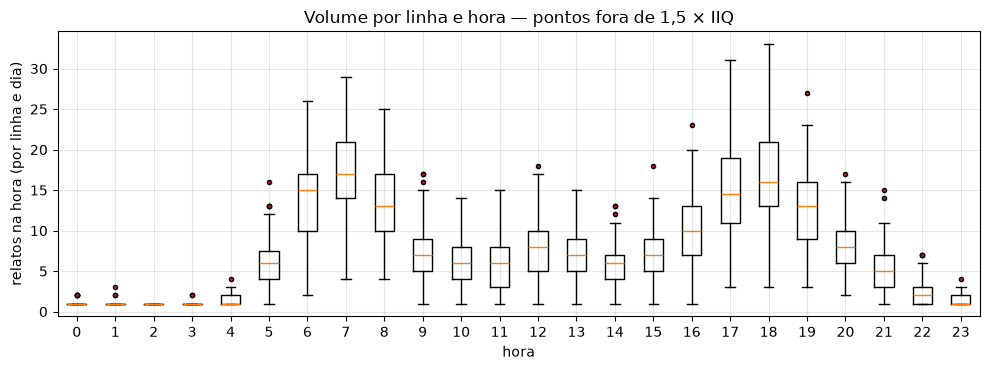

Células linha × dia × hora: 2786; fora de 1,5 × IIQ do mesmo par linha × hora: 57 (2.0%)
Por linha: {'018': 18, '071': 12, 'SUL': 11, '061': 11, '1076': 5}
Altos: 52 · baixos: 5
Dias com mais células fora: {'2026-10-20': 7, '2026-10-07': 4, '2026-10-08': 4} · dia da semana: {'2026-10-20': 'ter', '2026-10-07': 'qua', '2026-10-08': 'qui'}


,data,hora,linha_codigo,n_relatos,outlier
2561,2026-10-30,17,018,31,True
2563,2026-10-30,17,071,28,True
326,2026-10-08,7,071,28,True
1574,2026-10-20,19,SUL,27,True
761,2026-10-12,16,061,23,True
2572,2026-10-30,19,061,21,True
741,2026-10-12,12,061,18,True
1158,2026-10-16,15,061,18,True


In [13]:
celula = por_hora.groupby(["data", "hora", "linha_codigo"], as_index=False)["n_relatos"].sum()
grupo = celula.groupby(["linha_codigo", "hora"])["n_relatos"]
q1, q3 = grupo.transform(lambda s: s.quantile(0.25)), grupo.transform(lambda s: s.quantile(0.75))
iiq = q3 - q1
celula["outlier"] = (celula["n_relatos"] > q3 + 1.5 * iiq) | (celula["n_relatos"] < q1 - 1.5 * iiq)

fig, eixo = plt.subplots(figsize=(10, 3.8))
dados_box = [celula.loc[celula["hora"] == h, "n_relatos"] for h in range(24)]
eixo.boxplot(
    dados_box,
    positions=range(24),
    whis=1.5,
    flierprops={"markersize": 3, "markerfacecolor": "#b91c1c"},
)
eixo.set_xlabel("hora")
eixo.set_ylabel("relatos na hora (por linha e dia)")
eixo.set_title("Volume por linha e hora — pontos fora de 1,5 × IIQ")
plt.tight_layout()
plt.show()
outliers = celula[celula["outlier"]]
print(
    f"Células linha × dia × hora: {len(celula)}"
    f"; fora de 1,5 × IIQ do mesmo par linha × hora: {len(outliers)}"
    f" ({100 * len(outliers) / len(celula):.1f}%)"
)
print("Por linha:", outliers["linha_codigo"].value_counts().to_dict())
print(
    "Altos:",
    int((outliers["n_relatos"] > grupo.transform("median")[outliers.index]).sum()),
    "· baixos:",
    int((outliers["n_relatos"] <= grupo.transform("median")[outliers.index]).sum()),
)
por_data = outliers["data"].value_counts().head(3)
print(
    "Dias com mais células fora:",
    {str(d): int(n) for d, n in por_data.items()},
    "· dia da semana:",
    {str(d): DIAS[pd.Timestamp(d).day_of_week] for d in por_data.index},
)
outliers.sort_values("n_relatos", ascending=False).head(8)

**Interpretação: volume por linha e hora.** Comparamos cada célula linha × dia × hora com as outras do mesmo par linha × hora, porque comparar com todas as horas faria todo pico parecer outlier.
- 2% das células (57 de 2.786) ficam fora de 1,5 × IIQ;
- quase todas são **altas** (52 de 57);
- estão espalhadas por linhas e dias, sem concentração num dia ou numa linha.

O que explica isso é a atividade desigual dos usuários (poucos relatam muito), não um erro de coleta.

**Decisão: manter.** As contagens são consistentes (seção 1). O painel usa taxas, em que esse volume extra só dá mais precisão. Excluir essas horas tiraria justamente os momentos com mais informação.

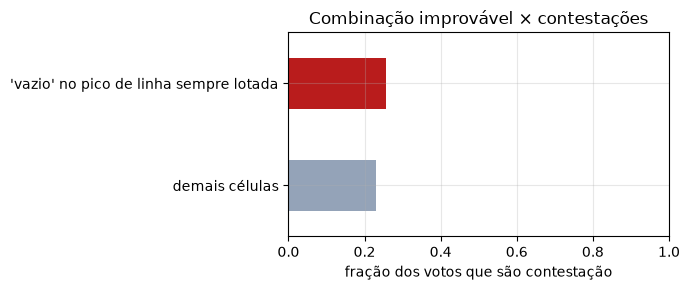

Linhas com taxa de lotado ≥ 60% no pico: ['061', '1076', 'SUL']
Células com a combinação improvável: 272 de 5130; relatos 'vazio' nelas: 339


,n_contestacoes,n_confirmacoes,n_relatos,n_vazio,contestações por voto
demais células,1957,6586,21397,3818,0.229
'vazio' no pico de linha sempre lotada,229,664,2299,339,0.256


In [14]:
taxa_linha_pico = por_hora[pico].groupby("linha_codigo")[["n_lotado", "n_relatos"]].sum()
sempre_lotadas = taxa_linha_pico.index[
    (taxa_linha_pico["n_lotado"] / taxa_linha_pico["n_relatos"]) >= 0.6
]
cel = por_hora.copy()
cel["improvavel"] = (
    cel["faixa_horaria"].isin(["pico_manha", "pico_tarde"])
    & cel["linha_codigo"].isin(sempre_lotadas)
    & (cel["n_vazio"] > 0)
)
votos = cel.groupby("improvavel")[
    ["n_contestacoes", "n_confirmacoes", "n_relatos", "n_vazio"]
].sum()
votos["contestações por voto"] = votos["n_contestacoes"] / (
    votos["n_contestacoes"] + votos["n_confirmacoes"]
)
votos.index = ["demais células", "'vazio' no pico de linha sempre lotada"]

fig, eixo = plt.subplots(figsize=(7, 3))
votos["contestações por voto"].plot.barh(ax=eixo, color=["#94a3b8", "#b91c1c"])
eixo.set_xlim(0, 1)
eixo.set_xlabel("fração dos votos que são contestação")
eixo.set_title("Combinação improvável × contestações")
plt.tight_layout()
plt.show()
print("Linhas com taxa de lotado ≥ 60% no pico:", list(sempre_lotadas))
print(
    f"Células com a combinação improvável: {int(cel['improvavel'].sum())} de {len(cel)}"
    f"; relatos 'vazio' nelas: {int(cel.loc[cel['improvavel'], 'n_vazio'].sum())}"
)
votos.round(3)

**Interpretação: combinação improvável.** A combinação improvável é "vazio" no pico de uma linha que, no pico, tem 60% ou mais de "lotado" (061, 1076 e SUL). São 339 relatos "vazio" em 272 células.

Nessas células, a fração de votos que são contestações é só um pouco maior (26% contra 23%). O sinal é fraco porque a célula mistura o relato improvável com todos os outros da mesma hora: na ouro não dá para ligar a contestação ao relato que a recebeu.

**Decisão: manter na análise.** Um "vazio" no pico pode ser verdade (veículo extra, início de linha). Quem decide se é abuso é a moderação, relato a relato (RF07), e removidos já saem da prata (L4).

O achado vira requisito para a fila de moderação: ordenar também por **"valor improvável para a linha e a hora"**, além do número de contestações.

relatos por usuário ativo: mediana 3.81; limite 5.49; dias acima: nenhum
% removidos: mediana 2.65; limite 3.86; dias acima: ['2026-10-11']
% contestações: mediana 23.19; limite 26.85; dias acima: nenhum


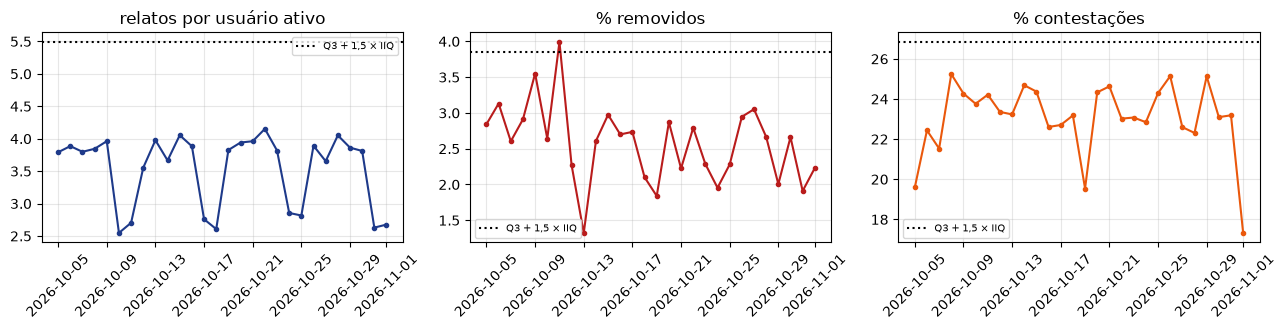

In [15]:
qd = qualidade.sort_values("data").copy()
qd["relatos por usuário ativo"] = qd["n_relatos_total"] / qd["n_usuarios_ativos"]
qd["% removidos"] = 100 * qd["n_removidos"] / qd["n_relatos_total"]
qd["% contestações"] = 100 * qd["n_contestacoes"] / (qd["n_contestacoes"] + qd["n_confirmacoes"])
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.4))
for eixo, coluna, cor in zip(
    eixos,
    ["relatos por usuário ativo", "% removidos", "% contestações"],
    ["#1e3a8a", "#b91c1c", "#ea580c"],
    strict=True,
):
    serie = qd[coluna]
    a, b = serie.quantile([0.25, 0.75])
    limite = b + 1.5 * (b - a)
    eixo.plot(qd["data"], serie, "o-", color=cor, markersize=3)
    eixo.axhline(limite, color="black", linestyle=":", label="Q3 + 1,5 × IIQ")
    eixo.set_title(coluna)
    eixo.tick_params(axis="x", rotation=45)
    eixo.legend(fontsize=7)
    acima = qd.loc[serie > limite, "data"].astype(str).tolist()
    print(
        f"{coluna}: mediana {serie.median():.2f}; limite {limite:.2f}"
        f"; dias acima: {acima or 'nenhum'}"
    )
plt.tight_layout()
plt.show()

**Interpretação: usuários anômalos.** A ouro não tem identificador de usuário. É uma regra de privacidade testada no pipeline, então a EDA não consegue apontar usuários. O que dá para ver são os sinais agregados por dia:
- **Relatos por usuário ativo e % de contestações:** nenhum dia fora do limite. Os trolls (2% dos usuários no mock) se diluem no total do dia.
- **% de removidos:** um dia fora (11/10, um domingo). Domingo tem metade do volume, e poucas remoções já pesam mais na porcentagem; não é um ataque.

**Decisão: manter** os dias. Identificar usuários anômalos continua sendo papel da moderação (RF07), que tem acesso ao usuário.

Para a análise de dados acompanhar isso sem quebrar a privacidade, a ouro pode ganhar uma tabela de **distribuição da atividade** (quantos usuários em cada faixa de relatos por dia e de taxa de contestação), sem identificador. Ver Conclusão.

## 5. Conclusão

### O que volta para a preparação (RD02 e RD03)

| # | Achado | Ajuste | Onde |
| --- | --- | --- | --- |
| 1 | A H3 pede "quente" separado por "com ar" e "sem ar", mas a ouro só tem contagens marginais | Acrescentar à `relatos_por_hora` o cruzamento conforto × ar (`n_quente_com_ar_funcionando`, `n_quente_sem_ar`…) | RD03, `ouro.py` |
| 2 | A H4 pede V de Cramér entre vaga e lotação, mas não há o cruzamento | Acrescentar o cruzamento vaga × lotação (`n_vaga_ocupada_lotado`…) | RD03, `ouro.py` |
| 3 | Usuários anômalos não aparecem nos agregados diários | Nova tabela `ouro.atividade_usuarios`: número de usuários por faixa de relatos/dia e de taxa de contestação, **sem identificador** | RD03, `ouro.py` + regra de privacidade |
| 4 | A operadora falta em ônibus e BRT, e a H2 por operadora fica sem teste | Importar o GTFS real com `agency.txt` | #25, `importar_gtfs` |
| 5 | A temperatura é 100% mock; a interpolação (L11) nunca foi exercitada com dado real | Validar a série do INMET e rodar esta EDA de novo | #26 |
| 6 | "Vazio" no pico de linha sempre lotada é um sinal útil para a moderação | Ordenar a fila de moderação também por valor improvável | RF07 |

As decisões de limpeza L1–L13 do RD02 se mantêm. Nenhum achado pede exclusão ou imputação de dados.

### Hipóteses (sobre DADOS MOCKADOS)

| Hipótese | Resultado no mock | Medida |
| --- | --- | --- |
| H1: lotação nos picos e nos TIs | Aparece | V = 0,30 (faixa); V = 0,16 (terminal); 72% × 59% de lotado no pico |
| H2: falha do ar varia entre linhas | Aparece entre linhas; por operadora, sem teste | V = 0,14; IC de 95% das pontas não se sobrepõem |
| H3: "quente" cresce com a temperatura | Aparece; o efeito do ar fica sem teste | Spearman ρ = 0,79 |
| H4: vaga PCD acompanha a lotação | Aparece, por medida indireta | V = 0,19 (faixa); ρ = 0,39 (células) |

Isso confirma que o pipeline e as medidas recuperam os padrões programados, não que os passageiros se comportem assim.

### O que segue para o dashboard (RD05)

| Página | Visualização | Cuidado |
| --- | --- | --- |
| Lotação | Mapa de calor linha × hora (taxa de lotado) | Esconder células com poucos relatos (madrugada) |
| Climatização | Ranking de falha do ar por linha, com IC de 95% e mínimo de 30 relatos | Aviso de que a taxa observada superestima a real (MNAR) |
| Climatização | Dispersão temperatura × taxa de "quente" | Separar por ar quando o ajuste 1 entrar |
| Acessibilidade | Barras empilhadas de vaga PCD por faixa horária, com a linha de lotação | Mostrar quantos informaram |
| Qualidade dos dados | Válidos, removidos, substituídos e contestações por dia | Porcentagem de domingo é mais instável |
| Filtro | Grupos de linhas pelo perfil de lotação | Útil quando houver o GTFS real |